# Step 3 — Brain → skin: does EEG announce skin conductance responses?

**Hypothesis.** Sympathetic activation shows up in the EEG *before* it reaches the skin: the literature reports a drop of EEG power (3–17 Hz, occipito-temporal) just before skin conductance response (SCR) peaks. We look for this delay with the cross-correlation tool validated in step 1, testing lags of **0 to 5 s** (EEG leading).

**Expected sign.** EEG power ↓ → skin conductance ↑ ⇒ **negative** correlation with the skin lagging behind the EEG (`latence(eeg_power, gsr, ..., sign=-1)`, delay > 0).

**Sub-steps**
1. **Load and inspect** GSR + EEG on the sample (P001 day 1, resting-state + artefact).
2. **Skin conductance**: quality control, SCR detection, phasic signal, expected skin latency, pre-video triggers, SCR × arousal. ← *here*
3. **EEG power envelopes**: theta (4–7 Hz) and alpha (8–12 Hz) per electrode, on a common time grid with the GSR.
4. **Delay**: cross-correlation EEG power → phasic GSR (0–5 s), and SCR-locked average of EEG power.
5. **Controls** (as in step 1.6): known shift, chance level (surrogates), stability, artefact confounds (movements, blinks, deep breaths trigger both EEG artefacts and SCRs).
6. **Emotion videos**: delay per video, high vs low arousal.
7. **Conclusion**.

**Data.** 3.1 uses the repo sample. From 3.2 on: the 20 participants of Maroua's autoencoder study (day 1, emotion-video + resting-state, PREPROCESSED), downloaded with `latence/download_data.py` into the folder given by `HABS_DATA` (default `../habs_data`, next to the repo).

Shared functions come from `latence/physio_utils.py` (step 1). New GSR / EEG functions will be moved there once validated.

## 3.1 — Load and inspect

Choice of data version:
- **EEG → PREPROCESSED** (0.5–48 Hz, average reference, ICA: blinks removed, 62 channels without T9/T10). Its filters may shift the EEG by a few milliseconds, which is negligible here: we look for delays of seconds between slow power envelopes and the skin.
- **GSR → either**: checked below, PREPROCESSED only removes the 50 Hz from the GSR (identical below 5 Hz, zero lag).

3.1 uses the repo sample (P001 day 1, no emotion-video segment), read explicitly from `sample/` whatever `HABS_DATA` says.

In [3]:
import os
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt, welch, find_peaks

ROOT = Path.cwd().parent if Path.cwd().name == "latence" else Path.cwd()
sys.path.insert(0, str(ROOT / "latence"))
from physio_utils import FS, load_bdf, bdf_path, load_metadata, task_windows

SAMPLE = ROOT / "sample"                                                    # 3.1: repo sample
VIDEO_DATA = Path(os.environ.get("HABS_DATA", ROOT.parent / "habs_data"))   # 3.2+: downloaded participants
SUBJ, DAY = "P001", 1
TASKS = ["resting-state", "artefact"]
print("sample:", SAMPLE, "| video data:", VIDEO_DATA, "(exists)" if VIDEO_DATA.is_dir() else "(MISSING: set HABS_DATA)")


sample: /Users/hugotrebert/Documents/4A/Habs-Hackathon/habs-team06/sample | video data: /Users/hugotrebert/Documents/4A/Habs-Hackathon/habs_data (exists)


In [4]:
def load_eeg_gsr(task, version="PREPROCESSED", subj=SUBJ, day=DAY):
    # Returns (DataFrame time_s + GSR + EEG channels, list of EEG channel names)
    _, sig, ch = load_bdf(bdf_path(task, subj, day, data=SAMPLE, version=version))
    eeg = ch.loc[ch.mne_type == "eeg", "bdf_label"].tolist()
    return sig[["time_s", "GSR", *eeg]].copy(), eeg

data, eeg_chans = {}, None
for task in TASKS:
    data[task], eeg_chans = load_eeg_gsr(task)
    g = data[task].GSR
    print(f"{task}: {len(g) / FS:.1f} s, GSR {g.min():.2f}–{g.max():.2f} µS (median {g.median():.2f}), "
          f"NaN GSR={g.isna().sum()}, {len(eeg_chans)} EEG channels")
print(eeg_chans)

Channel metadata: P001_day-1_task-resting-state_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.005 s
resting-state: 95.1 s, GSR 2.26–2.55 µS (median 2.39), NaN GSR=0, 62 EEG channels
Channel metadata: P001_day-1_task-artefact_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.004 s
artefact: 210.5 s, GSR 2.23–2.70 µS (median 2.51), NaN GSR=0, 62 EEG channels
['Fp1', 'Fp2', 'F9', 'F7', 'F3', 'Fz', 'F4', 'F8', 'F10', 'FC5', 'FC1', 'FC2', 'FC6', 'T7', 'C3', 'C4', 'T8', 'CP5', 'CP1', 'CP2', 'CP6', 'P9', 'P7', 'P3', 'Pz', 'P4', 'P8', 'P10', 'O1', 'O2', 'AF7', 'AF3', 'AF4', 'AF8', 'F5', 'F1', 'F2', 'F6', 'FC3', 'FCz', 'FC4', 'C5', 'C1', 'C2', 'C6', 'CP3', 'CP4', 'P5', 'P1', 'P2', 'P6', 'PO5', 'PO3', 'PO4', 'PO6', 'FT7', 'FT8', 'TP7', 'TP8', 'PO7', 'PO8', 'POz']


In [5]:
# GSR: CURATED vs PREPROCESSED
lowpass = lambda x, f: sosfiltfilt(butter(2, f, fs=FS, output="sos"), x)
for task in TASKS:
    _, cur, _ = load_bdf(bdf_path(task, SUBJ, DAY, data=SAMPLE, version="CURATED"))
    n = min(len(cur), len(data[task]))
    g_c, g_p = cur.GSR.to_numpy()[:n], data[task].GSR.to_numpy()[:n]
    f, p_c = welch(g_c, FS, nperseg=8192); _, p_p = welch(g_p, FS, nperseg=8192)
    ratio = lambda hz: p_p[np.argmin(abs(f - hz))] / p_c[np.argmin(abs(f - hz))]
    print(f"{task}: raw corr {np.corrcoef(g_c, g_p)[0, 1]:.3f}, corr below 5 Hz {np.corrcoef(lowpass(g_c, 5), lowpass(g_p, 5))[0, 1]:.4f}, "
          f"power ratio PRE/CUR at 1 Hz {ratio(1):.3f}, 50 Hz {ratio(50):.3f}, 100 Hz {ratio(100):.3f}")

Channel metadata: P001_day-1_task-resting-state_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.005 s
resting-state: raw corr 0.878, corr below 5 Hz 1.0000, power ratio PRE/CUR at 1 Hz 0.997, 50 Hz 0.000, 100 Hz 1.001
Channel metadata: P001_day-1_task-artefact_multimodal.record_map
Gaze: stored 166 Hz, effective 166.358 Hz, onset 0.002 s
artefact: raw corr 0.963, corr below 5 Hz 1.0000, power ratio PRE/CUR at 1 Hz 1.000, 50 Hz 0.000, 100 Hz 1.006


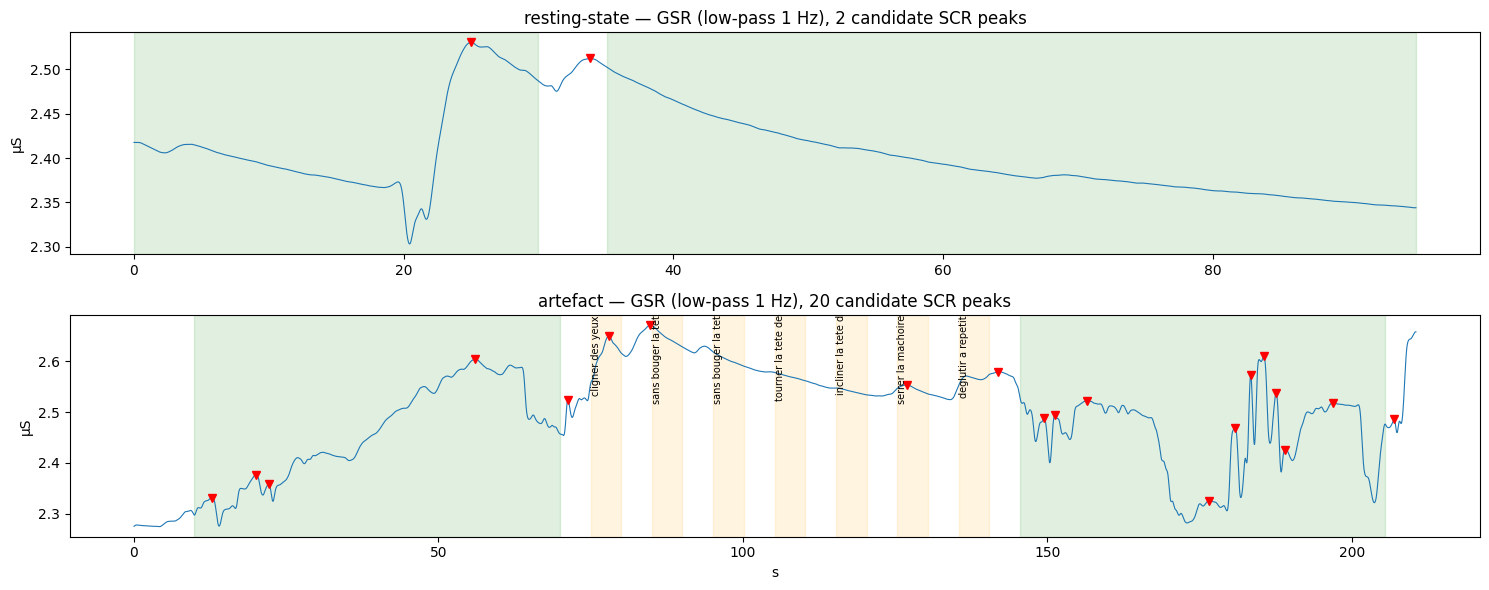

In [6]:
# GSR over each segment, with event windows (green = rest, orange = instructed movement) and candidate SCR peaks
fig, axs = plt.subplots(len(TASKS), 1, figsize=(15, 6))
for ax, task in zip(axs, TASKS):
    t, g = data[task].time_s.to_numpy(), lowpass(data[task].GSR.to_numpy(), 1.0)
    pk, _ = find_peaks(g, prominence=0.02, distance=int(FS))     # rough: rises of at least 0.02 µS
    ax.plot(t, g, lw=.8); ax.plot(t[pk], g[pk], "rv", ms=6)
    for on, off, txt in task_windows(task, SUBJ, DAY, data=SAMPLE, version="PREPROCESSED"):
        ax.axvspan(on, off, color="green" if txt.startswith("repos") else "orange", alpha=.12)
        if not txt.startswith("repos"):
            ax.text(on, ax.get_ylim()[1], txt[:18], fontsize=7, rotation=90, va="top")
    ax.set_title(f"{task} — GSR (low-pass 1 Hz), {len(pk)} candidate SCR peaks"); ax.set_ylabel("µS")
axs[-1].set_xlabel("s")
plt.tight_layout(); plt.show()

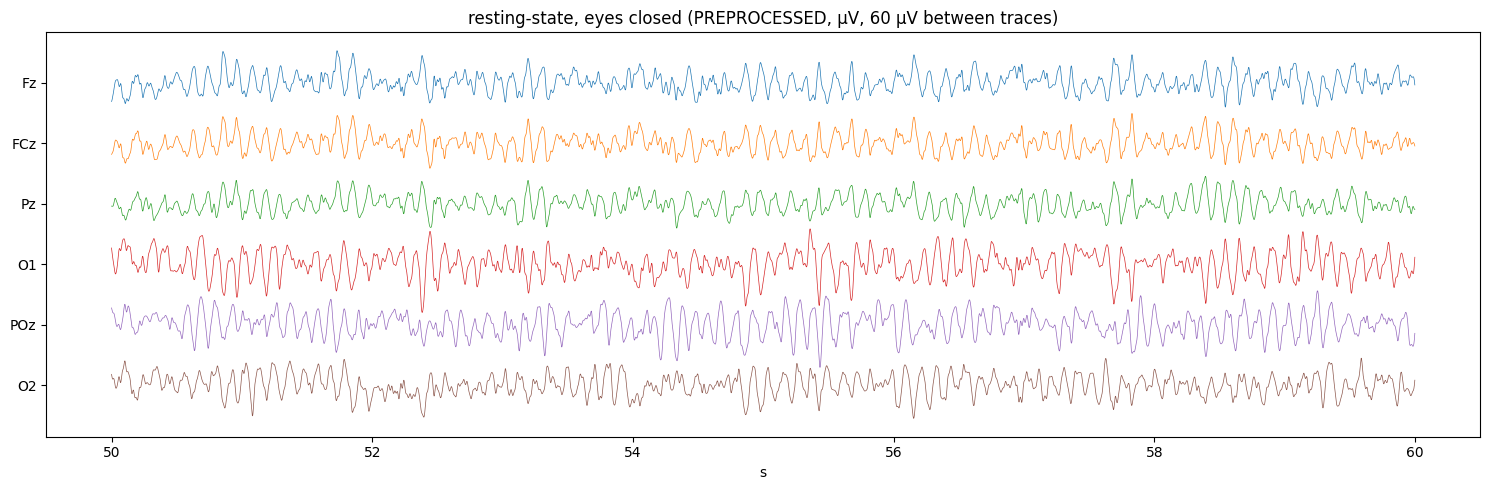

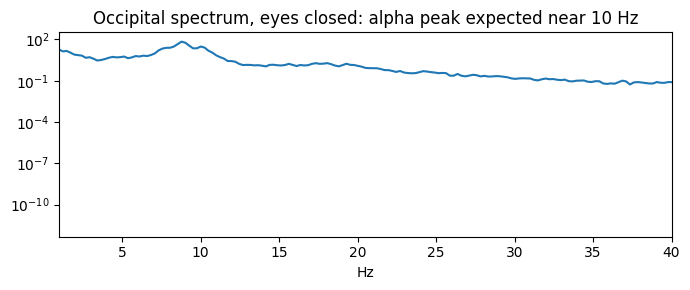

In [7]:
# EEG at a glance: occipital / parietal / frontal channels, 10 s of the eyes-closed rest
show = ["Fz", "FCz", "Pz", "O1", "POz", "O2"]          # no Cz (online reference) nor Oz in this montage
df = data["resting-state"]
z = (df.time_s >= 50) & (df.time_s < 60)
fig, ax = plt.subplots(figsize=(15, 5))
for k, c in enumerate(show):
    ax.plot(df.time_s[z], df[c][z] - 60 * k, lw=.5)
ax.set_yticks([-60 * k for k in range(len(show))], show); ax.set_xlabel("s")
ax.set_title("resting-state, eyes closed (PREPROCESSED, µV, 60 µV between traces)")
plt.tight_layout(); plt.show()

f, p = welch(df.loc[(df.time_s >= 35), ["O1", "POz", "O2"]].to_numpy().T, FS, nperseg=4096)
plt.figure(figsize=(7, 3)); plt.semilogy(f, p.mean(0)); plt.xlim(1, 40)
plt.title("Occipital spectrum, eyes closed: alpha peak expected near 10 Hz"); plt.xlabel("Hz")
plt.tight_layout(); plt.show()

**Observations (P001)**
- **GSR versions**: PREPROCESSED = CURATED with the 50 Hz removed (power ratio 0 at 50 Hz, 1 elsewhere; correlation 1.000 below 5 Hz, zero lag). For the skin, the version does not matter.
- **Low conductance**: 2.2–2.7 µS, at the low end of the usual range (≈ 2–20 µS) → small responses (hundredths to tenths of a µS).
- **resting-state**: a single clear SCR (rise of ~0.2 µS between 20 and 25 s, preceded by a sharp dip), then a slow tonic decline. Too few events to estimate a delay.
- **artefact**: many fluctuations in both rest windows, but several are **sharp drops** (down to −0.35 µS/s, e.g. around 175–185 s). A real SCR rises within 1–3 s and recovers slowly, so these fast drops are most likely artefacts (finger movement or electrode pressure). The 20 "peaks" of the simple detector are therefore not all SCRs → a proper SCR detection is needed (3.2).
- Instructed movements barely trigger SCRs here (GSR range < 0.17 µS per 5 s movement window).
- **EEG** (PREPROCESSED, 62 channels, no Cz/Oz): clean at rest (median std 8–9 µV), with a strong occipital alpha rhythm with eyes closed (peak at 8.8 Hz, 18× the power at 4 Hz). Very large artefacts only during head movements (median std 100–400 µV), which are outside the rest windows.

**Consequence.** The sample is enough to **build and test** the pipeline (3.2–3.5), but not to answer the question: ~1 clean SCR at rest, noisy GSR in the artefact rest windows. The answer needs the **emotion-video** segments (3.6), where every 10 s video can trigger an SCR.


## 3.2 — Skin conductance: quality control, SCR detection, phasic signal

From here on: the **20 participants** of Maroua's study, day 1, **emotion-video** segment, PREPROCESSED (GSR = CURATED without 50 Hz, see 3.1).

Choices:
- **Read only the GSR channel** (pyedflib), converted to µS with the loader's calibration (`uV_to_uS`). Loading the whole BDF (82 channels) is much slower.
- **Smoothing**: low-pass 1 Hz, zero phase, then a 20 Hz grid (as in step 1). SCRs last several seconds, so nothing useful is lost.
- **Quality control**: (1) *flat sensor*: no variation at all (electrodes not connected); (2) *floor at 1 µS*: the loader's calibration table stops at 1 µS (1000 kΩ), lower values are clamped, so responses starting below 1 µS are invisible.
- **SCR detection** (trough-to-peak): peaks rising at least **0.02 µS** above their surroundings; onset = lowest point in the 5 s before the peak. A **spike** (rise shorter than 1 s, then more than half of the amplitude lost within the next second) is flagged as a likely **artefact**: a real SCR rises over 1–3 s and recovers over several seconds (fast-drop pattern seen in 3.1). A looser rule (half lost within 2 s) flagged 20–60 % of the SCRs, including clean ones.
- **Phasic signal = positive slope of the GSR** (µS/s), not a high-pass filter. A zero-phase high-pass spreads each SCR over ±10 s, including *before* its onset; it would create an artificial dip before the skin response, exactly where we look for the EEG effect. The slope stays local in time (±0.5 s from the 1 Hz smoothing).
- **Check, as in step 1**: a skin response to a stimulus starts **1–3 s** after it. If the slope averaged on video onsets does not peak there, the timing (markers, smoothing) is wrong.


In [8]:
import pyedflib
sys.path.insert(0, str(ROOT / "starting_notebooks"))
from bdf_loader import uV_to_uS

PARTICIPANTS = ("P001 P017 P020 P086 P097 P126 P128 P129 P131 P137 "
                "P174 P186 P187 P194 P201 P217 P219 P308 P310 P459").split()
FG = 20.0   # Hz, common grid for GSR (and later EEG power)


def read_gsr(subj, task="emotion-video", day=1, data=VIDEO_DATA, version="PREPROCESSED"):
    """GSR channel only, in µS, at FS."""
    with pyedflib.EdfReader(str(bdf_path(task, subj, day, data=data, version=version))) as r:
        return uV_to_uS(r.readSignal(r.getSignalLabels().index("GSR")))


def smooth_gsr(g, fs=FS, fs_out=FG):
    """Low-pass 1 Hz (zero phase), then decimation to fs_out."""
    return sosfiltfilt(butter(2, 1.0, fs=fs, output="sos"), g)[::int(fs / fs_out)]


def gsr_qc(g):
    """Range of the smoothed GSR (µS) and % of time stuck at the 1 µS calibration floor."""
    return {"range_uS": np.percentile(g, 99) - np.percentile(g, 1), "median_uS": np.median(g),
            "floor_pct": 100 * np.mean(g <= 1.001)}


def scr_detect(g, fs=FG, min_amp=0.02, max_rise=5.0):
    """SCRs as a DataFrame (onset_s, peak_s, amp_uS, artefact).

    Peak = local maximum of prominence >= min_amp; onset = lowest point in the max_rise s before
    (not before the previous peak); artefact = spike: rise < 1 s and more than half of the amplitude lost within 1 s.
    Onsets on the 1 µS floor are dropped (the true onset is hidden)."""
    pk, _ = find_peaks(g, prominence=min_amp)
    rows, prev = [], 0
    for b in pk:
        lo = max(prev, b - int(max_rise * fs))
        a = lo + np.argmin(g[lo:b + 1])
        prev = b
        amp = g[b] - g[a]
        if amp < min_amp or a == b or g[a] <= 1.001:
            continue
        drop = g[b] - g[min(b + int(fs), len(g) - 1)]
        rows.append((a / fs, b / fs, amp, (b - a) / fs < 1.0 and drop > 0.5 * amp))
    return pd.DataFrame(rows, columns=["onset_s", "peak_s", "amp_uS", "artefact"])


def scr_driver(g, fs=FG):
    """Phasic signal: positive part of the GSR slope (µS/s)."""
    return np.clip(np.gradient(g) * fs, 0, None)


def video_onsets(subj, day=1, data=VIDEO_DATA):
    return [on for on, off, txt in task_windows("emotion-video", subj, day, data=data, version="PREPROCESSED")
            if txt and txt.endswith(".mp4")]


In [9]:
# Load + quality control (≈ 1 min for 20 participants)
gsr, rows = {}, []
for p in PARTICIPANTS:
    gsr[p] = smooth_gsr(read_gsr(p))
    rows.append({"participant": p, "duration_s": len(gsr[p]) / FG, "n_videos": len(video_onsets(p)), **gsr_qc(gsr[p])})
qc = pd.DataFrame(rows).set_index("participant")
qc["flat"] = qc.range_uS < 0.05            # no SCR possible below this range
qc["floor"] = qc.floor_pct > 5              # long periods below 1 µS: kept, but responses partly hidden
GOOD = qc.index[~qc.flat].tolist()
print(f"usable: {len(GOOD)}/{len(qc)} — flat sensor: {qc.index[qc.flat].tolist()}, floor > 5 %: {qc.index[qc.floor].tolist()}")
qc.round(3)


usable: 18/20 — flat sensor: ['P017', 'P097'], floor > 5 %: ['P219', 'P308']


,duration_s,n_videos,range_uS,median_uS,floor_pct,flat,floor
participant,,,,,,,
P001,857.0,36,0.304,2.401,0.000,False,False
P017,695.0,36,0.021,7.819,0.000,True,False
P020,918.0,36,1.801,4.722,0.000,False,False
P086,780.0,36,1.180,2.527,0.000,False,False
P097,687.0,36,0.008,7.868,0.000,True,False
P126,734.0,35,0.989,1.232,0.061,False,False
P128,601.0,35,2.927,6.339,0.000,False,False
P129,819.0,36,2.146,6.868,0.000,False,False
P131,717.0,36,0.761,3.326,0.000,False,False


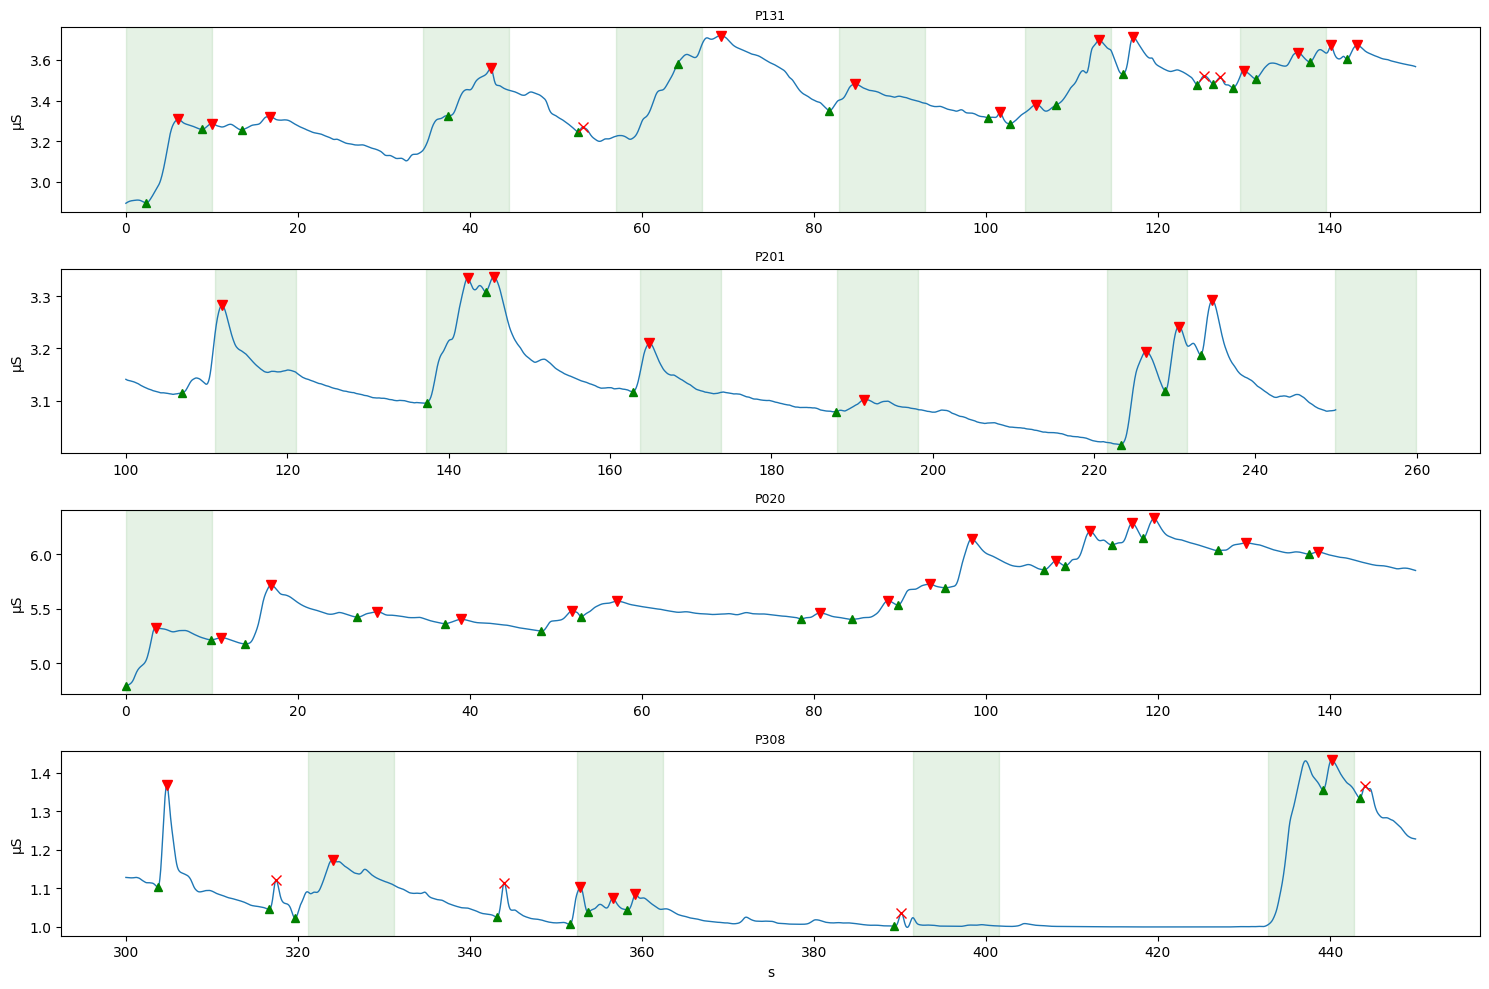

In [10]:
# Detected SCRs on four participants (green ▲ onset, red ▼ peak, red × artefact; shaded = videos)
show = [("P131", 0, 150), ("P201", 100, 250), ("P020", 0, 150), ("P308", 300, 450)]
fig, axs = plt.subplots(len(show), 1, figsize=(15, 10))
for ax, (p, t0, t1) in zip(axs, show):
    g = gsr[p]; t = np.arange(len(g)) / FG; z = (t >= t0) & (t < t1)
    ax.plot(t[z], g[z], lw=1)
    s = scr_detect(g)
    s = s[(s.onset_s >= t0) & (s.onset_s < t1)]
    ax.plot(s.onset_s, g[(s.onset_s * FG).astype(int)], "g^", ms=6)
    for art, mk in [(False, "rv"), (True, "rx")]:
        k = s[s.artefact == art]
        ax.plot(k.peak_s, g[(k.peak_s * FG).astype(int)], mk, ms=7)
    for on in video_onsets(p):
        if t0 <= on < t1:
            ax.axvspan(on, on + 10, color="green", alpha=.1)
    ax.set_title(p, fontsize=9); ax.set_ylabel("µS")
axs[-1].set_xlabel("s"); plt.tight_layout(); plt.show()


,n_scr,per_min,artefact_pct,median_amp_uS,videos_with_scr_1_4s_pct
participant,,,,,
P001,27,1.89,0.00,0.05,5.56
P020,46,3.01,19.57,0.06,5.56
P086,8,0.62,0.00,0.03,0.00
P126,42,3.43,2.38,0.06,11.43
P128,22,2.20,4.55,0.12,5.71
P129,50,3.66,0.00,0.13,19.44
P131,94,7.87,17.02,0.07,36.11
P137,26,2.04,0.00,0.07,8.33
P174,37,1.67,8.11,0.08,18.52


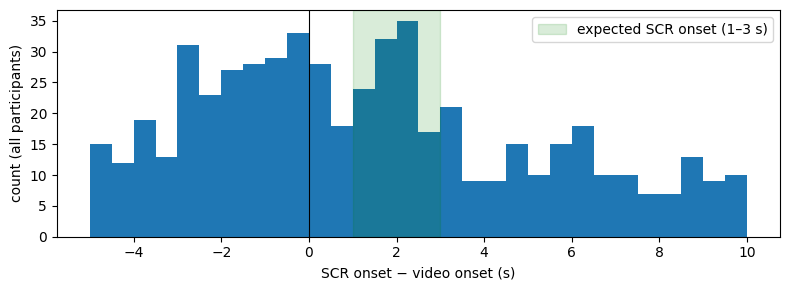

In [11]:
# SCRs per participant, and where they start relative to video onsets
scr, rel, rows = {}, [], []
for p in GOOD:
    scr[p] = s = scr_detect(gsr[p])
    on = s.onset_s[~s.artefact].to_numpy()
    vids = video_onsets(p)
    rel.append(np.concatenate([on[(on >= v - 5) & (on < v + 10)] - v for v in vids]))
    rows.append({"participant": p, "n_scr": len(s), "per_min": len(s) / (len(gsr[p]) / FG) * 60,
                 "artefact_pct": 100 * s.artefact.mean(), "median_amp_uS": s.amp_uS.median(),
                 "videos_with_scr_1_4s_pct": 100 * np.mean([((on >= v + 1) & (on < v + 4)).any() for v in vids])})
display(pd.DataFrame(rows).set_index("participant").round(2))

plt.figure(figsize=(8, 3))
plt.hist(np.concatenate(rel), bins=np.arange(-5, 10.5, 0.5))
plt.axvline(0, color="k", lw=.8); plt.axvspan(1, 3, color="green", alpha=.15, label="expected SCR onset (1–3 s)")
plt.xlabel("SCR onset − video onset (s)"); plt.ylabel("count (all participants)"); plt.legend()
plt.tight_layout(); plt.show()


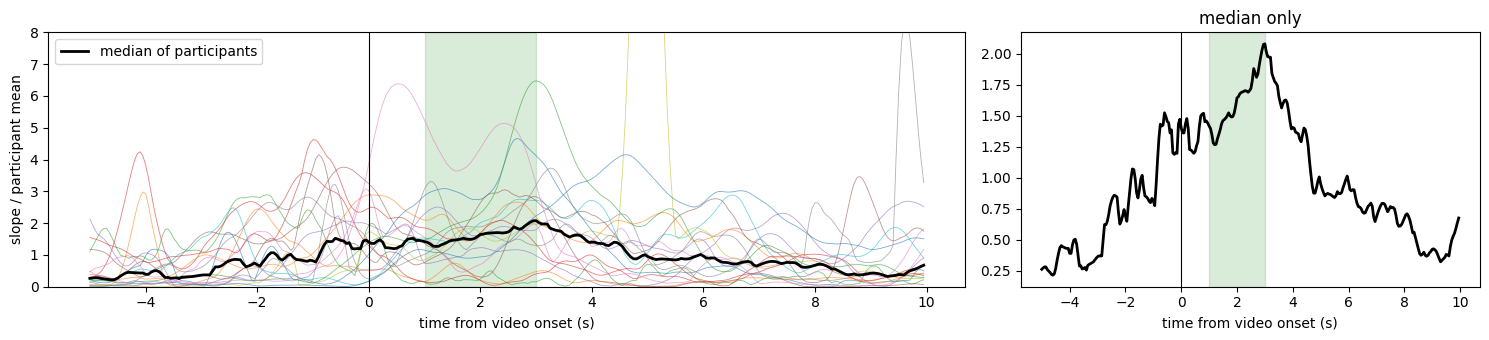

median slope: peak at +3.00 s; level x0.34 at −5..−3 s, x1.32 at video onset, x1.75 at 2..4 s


In [12]:
# Phasic signal (positive GSR slope) averaged on video onsets, per participant (normalised by its own mean)
lags = np.arange(-5, 10, 1 / FG)
locked = {}
for p in GOOD:
    d = scr_driver(gsr[p])
    ep = [d[int(v * FG) - 100:int(v * FG) + 200] for v in video_onsets(p) if v >= 5 and int(v * FG) + 200 <= len(d)]
    locked[p] = np.mean(ep, axis=0) / d.mean()
L = pd.DataFrame(locked, index=lags)

fig, axs = plt.subplots(1, 2, figsize=(15, 3.5), gridspec_kw={"width_ratios": [2, 1]})
axs[0].plot(lags, L.to_numpy(), lw=.6, alpha=.6)
axs[0].plot(lags, L.median(axis=1), "k", lw=2, label="median of participants")
axs[1].plot(lags, L.median(axis=1), "k", lw=2)
for ax in axs:
    ax.axvline(0, color="k", lw=.8); ax.axvspan(1, 3, color="green", alpha=.15); ax.set_xlabel("time from video onset (s)")
axs[0].set_ylabel("slope / participant mean"); axs[0].set_ylim(0, 8); axs[0].legend(); axs[1].set_title("median only")
plt.tight_layout(); plt.show()
med = L.median(axis=1)
print(f"median slope: peak at {med.loc[0:8].idxmax():+.2f} s; level x{med.loc[-5:-3].mean():.2f} at −5..−3 s, "
      f"x{med.loc[-0.5:0.5].mean():.2f} at video onset, x{med.loc[2:4].mean():.2f} at 2..4 s")


### 3.2b — What triggers the SCRs just before the videos?

The Dataset Paper (Figure 1C) gives the trial timeline, **not marked in the data** (only video onsets are):

| 1 · Prepare | 2 · Watch video | 3 · Rate experience | 4 · Select emotions |
|---|---|---|---|
| 5 s, black screen "Prepare yourself" | 10 s, with sound | valence / arousal / dominance sliders, until response | up to 3 emotions, then "Continue", until response |

So each video is preceded, **5 s earlier**, by a click on "Continue" and a switch to a black screen. Candidate triggers of the pre-video SCRs: that click / screen change (and the anticipation of the next video), the rating itself, or the end of the previous video. Below: SCR onset rate aligned on each candidate, and the place of resting-state and artefact in the session.


previous video end → next video onset: median 14.0 s (5–95 %: 7.4–27.1), i.e. ≈ 9 s of rating + 5 s of preparation


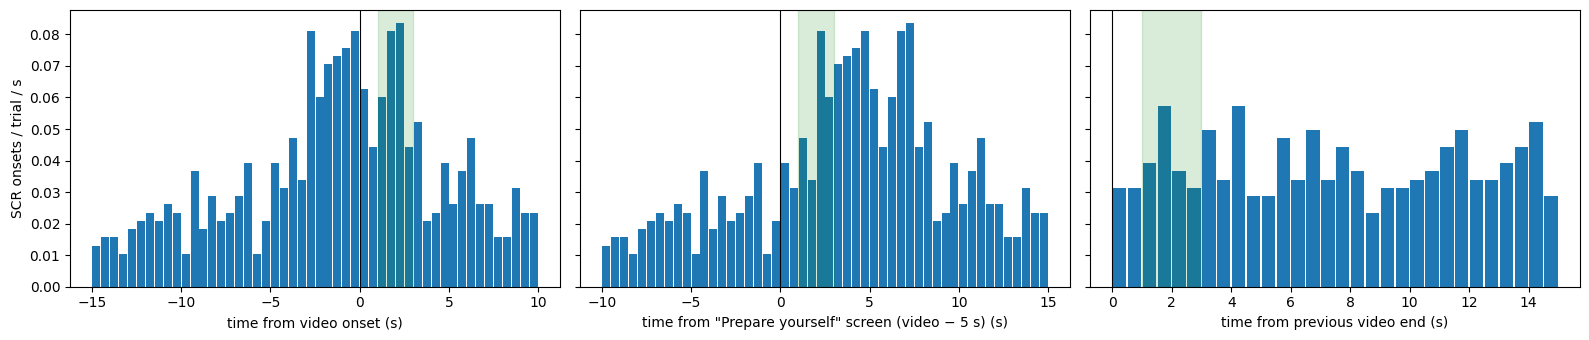

segments in the session (metadata clock, s):
  P001 {'resting-state': (154, 249), 'emotion-video': (251, 1108), 'artefact': (1974, 2185)}
  P131 {'resting-state': (227, 322), 'emotion-video': (325, 1042), 'artefact': (1903, 2114)}
  P201 {'resting-state': (212, 307), 'emotion-video': (310, 1702)}
  P459 {'resting-state': (492, 587), 'emotion-video': (1879, 3628)}


In [13]:
# Inter-video gap and SCR onset rate aligned on three candidate events
from physio_utils import load_metadata

trials, gaps = {}, []
for p in GOOD:
    w = [(on, off) for on, off, txt in task_windows("emotion-video", p, 1, data=VIDEO_DATA, version="PREPROCESSED")
         if txt and txt.endswith(".mp4")]
    trials[p] = [(w[i - 1][1], on) for i, (on, off) in enumerate(w) if i > 0]   # (previous video end, video onset)
    gaps += [on - prev_end for prev_end, on in trials[p]]
print(f"previous video end → next video onset: median {np.median(gaps):.1f} s (5–95 %: {np.percentile(gaps, 5):.1f}–{np.percentile(gaps, 95):.1f}), "
      f"i.e. ≈ {np.median(gaps) - 5:.0f} s of rating + 5 s of preparation")


def onset_rate(align, lo, hi, step=0.5):
    """SCR onsets (spikes excluded) per trial and per second around align(prev_end, video_onset).
    Only onsets between the previous video end and the end of the current video are counted."""
    bins = np.arange(lo, hi + step, step); h = np.zeros(len(bins) - 1); n = 0
    for p in GOOD:
        on = scr[p].onset_s[~scr[p].artefact].to_numpy()
        for prev_end, vo in trials[p]:
            ok = (on >= prev_end) & (on < vo + 10)
            h += np.histogram(on[ok] - align(prev_end, vo), bins)[0]; n += 1
    return bins[:-1] + step / 2, h / n / step

fig, axs = plt.subplots(1, 3, figsize=(16, 3.5), sharey=True)
for ax, (name, f, lo, hi) in zip(axs, [("video onset", lambda pe, vo: vo, -15, 10),
                                         ('"Prepare yourself" screen (video − 5 s)', lambda pe, vo: vo - 5, -10, 15),
                                         ("previous video end", lambda pe, vo: pe, 0, 15)]):
    t, r = onset_rate(f, lo, hi)
    ax.bar(t, r, width=0.45); ax.axvline(0, color="k", lw=.8); ax.axvspan(1, 3, color="green", alpha=.15)
    ax.set_xlabel(f"time from {name} (s)")
axs[0].set_ylabel("SCR onsets / trial / s"); plt.tight_layout(); plt.show()

print("segments in the session (metadata clock, s):")
for p in ["P001", "P131", "P201", "P459"]:
    seg = load_metadata(p, 1, data=VIDEO_DATA, version="PREPROCESSED")["dataset_export"]["segments"]
    print(" ", p, {k: (round(v["metadata_time_origin_s"]), round(v["metadata_time_origin_s"] + v["duration_s"])) for k, v in seg.items()})


In [14]:
# Share of SCRs by likely trigger
count = {"after the prepare screen (video −4 … +1 s)": 0, "after the video onset (+1 … +4 s)": 0, "neither (spontaneous, rating…)": 0}
for p in GOOD:
    on = scr[p].onset_s[~scr[p].artefact].to_numpy()
    cue, vid = np.zeros(len(on), bool), np.zeros(len(on), bool)
    for v in video_onsets(p):
        cue |= (on >= v - 4) & (on < v + 1)      # 1–6 s after the prepare screen, before the video can act
        vid |= (on >= v + 1) & (on < v + 4)
    for k, m in zip(count, [cue & ~vid, vid, ~cue & ~vid]):
        count[k] += m.sum()
n = sum(count.values())
pd.Series({k: f"{v} ({100 * v / n:.0f} %)" for k, v in count.items()}, name=f"{n} SCRs, 18 participants")


after the prepare screen (video −4 … +1 s)    249 (31 %)
after the video onset (+1 … +4 s)             138 (17 %)
neither (spontaneous, rating…)                406 (51 %)
Name: 793 SCRs, 18 participants, dtype: str

### 3.2c — Do SCRs follow high-arousal videos more often?

Only 10–20 % of the videos are followed by an SCR within 1–4 s. Before building on SCRs (steps 3 and 4), a quick check: is the presence or size of an SCR related to the arousal rating?

- Ratings from `labels_train.csv` only (day 1, `flagged_outliers` ≠ 1), linked to the video onset by `start_marker` = `marker_id`.
- Per trial: **SCR early** (onset 1–4 s after video onset), **SCR any** (onset 1–11 s: the whole video, content can act at any time), **amplitude** (largest SCR with onset 1–11 s, 0 if none), and as a **negative control** the SCR after the prepare screen (onset −4…+1 s), which happens before the video is known and should not depend on its rating.
- Within each participant: Spearman correlation with the rating, and high vs low third of that participant's ratings; group test = Wilcoxon on the per-participant values. Then the same correlation controlling for time in the session (habituation).


In [15]:
from scipy.stats import spearmanr, wilcoxon, rankdata

labels = pd.read_csv(VIDEO_DATA / "labels_train.csv", na_values=["TESTSUBJECT"])
labels = labels[(labels.day == 1) & labels.rating_arousal.notna() & (labels.flagged_outliers != 1)]


def onsets_by_marker(subj, day=1):
    """Video onset (s, in the emotion-video segment) for each marker_id."""
    m = load_metadata(subj, day, data=VIDEO_DATA, version="PREPROCESSED")
    seg = m["dataset_export"]["segments"]["emotion-video"]
    t0, dur = seg["metadata_time_origin_s"], seg["duration_s"]
    return {e["marker_id"]: e["onset_s"] - t0 for e in m["events"]
            if e.get("trial_type") == "emotion_video" and 0 <= e["onset_s"] - t0 < dur}


rows = []
for p in GOOD:
    s = scr[p][~scr[p].artefact]
    onset_of = onsets_by_marker(p)
    for r in labels[labels.participant_id == p].itertuples():
        v = onset_of.get(int(r.start_marker))
        if v is None or v < 5 or v + 11 > len(gsr[p]) / FG:
            continue
        whole = s[(s.onset_s >= v + 1) & (s.onset_s < v + 11)]
        rows.append({"participant": p, "arousal": r.rating_arousal, "onset_s": v,
                     "scr_early": ((s.onset_s >= v + 1) & (s.onset_s < v + 4)).any(),
                     "scr_any": len(whole) > 0, "amp": whole.amp_uS.max() if len(whole) else 0.0,
                     "cue_scr (control)": ((s.onset_s >= v - 4) & (s.onset_s < v + 1)).any()})
trials_scr = pd.DataFrame(rows)
rank = trials_scr.groupby("participant").arousal.rank(pct=True)
trials_scr["level"] = np.select([rank > 2 / 3, rank <= 1 / 3], ["high", "low"], "mid")
print(f"{len(trials_scr)} rated trials, {trials_scr.participant.nunique()} participants "
      f"({trials_scr.groupby('participant').size().min()}–{trials_scr.groupby('participant').size().max()} per participant)")


def partial_rho(d, y, x, z):
    """Spearman correlation of y and x after removing the linear effect of z (on ranks)."""
    Y, X, Z = (rankdata(d[c]).astype(float) for c in (y, x, z))
    res = lambda a: a - np.polyval(np.polyfit(Z, a, 1), Z)
    return np.corrcoef(res(Y), res(X))[0, 1]


out = []
for col in ["scr_early", "scr_any", "amp", "cue_scr (control)"]:
    g = trials_scr.groupby("participant")
    rho = g.apply(lambda d: spearmanr(d.arousal, d[col]).statistic, include_groups=False).dropna()
    rho_t = g.apply(lambda d: partial_rho(d, col, "arousal", "onset_s") if d[col].nunique() > 1 else np.nan,
                    include_groups=False).dropna()
    hl = trials_scr[trials_scr.level != "mid"].groupby(["participant", "level"])[col].mean().unstack()
    out.append({"measure": col, "high third": hl["high"].mean(), "low third": hl["low"].mean(),
                "median rho": rho.median(), "rho > 0": f"{(rho > 0).sum()}/{len(rho)}", "p (rho)": wilcoxon(rho).pvalue,
                "median rho | time": rho_t.median(), "p (rho | time)": wilcoxon(rho_t).pvalue})
pd.DataFrame(out).set_index("measure").round(3)


659 rated trials, 18 participants (20–52 per participant)


/var/folders/7v/fbnqvhfs0cz5mgm8yzrjl3y00000gn/T/ipykernel_58619/2428587611.py:46: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = g.apply(lambda d: spearmanr(d.arousal, d[col]).statistic, include_groups=False).dropna()
/var/folders/7v/fbnqvhfs0cz5mgm8yzrjl3y00000gn/T/ipykernel_58619/2428587611.py:46: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = g.apply(lambda d: spearmanr(d.arousal, d[col]).statistic, include_groups=False).dropna()
/var/folders/7v/fbnqvhfs0cz5mgm8yzrjl3y00000gn/T/ipykernel_58619/2428587611.py:46: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  rho = g.apply(lambda d: spearmanr(d.arousal, d[col]).statistic, include_groups=False).dropna()


,high third,low third,median rho,rho > 0,p (rho),median rho | time,p (rho | time)
measure,,,,,,,
scr_early,0.179,0.155,0.073,11/17,0.517,0.068,0.611
scr_any,0.364,0.254,0.161,12/17,0.003,0.124,0.002
amp,0.100,0.028,0.170,12/17,0.004,0.171,0.003
cue_scr (control),0.342,0.358,-0.046,6/18,0.981,-0.017,0.734


**Observations (20 participants, day 1)** — (numbers from a full run on 20 November)
- **Unusable**: P017 and P097 (flat GSR ≈ 7.8 µS: raw voltage near 0 V, i.e. electrodes not connected). **18 participants left.**
- **1 µS floor**: P219 and P308 spend 13 % and 7 % of the time clamped at 1 µS (low conductance); SCRs starting there are dropped. Kept, but their responses are partly hidden.
- **SCRs**: 0.6 to 8 per minute depending on the person, median amplitude 0.03–0.15 µS. Spikes (artefacts) are almost absent in most participants but reach 17–28 % in P020, P131, P308 and P459 (noisy GSR).
- **Expected latency is found on average**: the median phasic signal peaks at **+3.0 s** after video onset (×1.75 the participant mean at 2–4 s, ×0.34 at −5…−3 s): steepest rise of the SCR, i.e. SCR onsets ≈ 1–3 s after the video starts. Video markers and smoothing are consistent with the known skin latency. On average only: individual curves vary a lot.
- **But most videos trigger no SCR**: an SCR starts 1–4 s after video onset in 0–54 % of the videos depending on the person (median ≈ 14 %). Many trials will have no skin response at all.
- **Responses before video onset = responses to the "Prepare yourself" screen (3.2b)**: the SCR onset rate doubles **2 s after the prepare screen** (i.e. after the "Continue" click and the switch to a black screen), stays high until the video, then peaks again 1.5–2 s after video onset. Aligned on the previous video end, the rate is flat. Of 793 SCRs: **31 %** follow the prepare screen, **17 %** follow the video onset, **51 %** are tied to neither (spontaneous or during rating, ≈ 9 s on average).
- **Not resting-state, not artefact**: resting-state ends 2–3 s before the emotion-video segment (P001, P131, P201), so it only precedes the first video; the artefact block is recorded much later in the session. Nothing more to download for this question.

- **SCRs carry arousal information (3.2c, 659 rated trials)**: an SCR starting anywhere in the video (1–11 s) follows **36 %** of the videos in a participant's high-arousal third vs **25 %** in the low third; within-participant correlation with the rating: median ρ = +0.16 (positive in 12/17, p = 0.003), amplitude ρ = +0.17 (p = 0.004). It holds after controlling for time in the session (ρ = +0.12, p = 0.002), so it is not habituation. **Not in the first seconds**: an SCR 1–4 s after onset is unrelated to arousal (p = 0.52), consistent with the response to the video onset itself being generic. The negative control (SCR after the prepare screen, before the video is known) is unrelated as expected (p = 0.98). Small effect, 18 participants, uncorrected for the 3 measures tested.

**Consequences for the next steps**
- **For step 4**: count SCRs over the whole video, with onsets ≥ 1 s after video onset, rather than the first seconds or a level change against a pre-video baseline.
- For the brain → skin delay, use **SCR onsets** (event-locked EEG power) and the **phasic slope** (cross-correlation), never a high-pass filtered GSR.
- **Two external triggers per trial**, 5 s apart (prepare screen + click, then video onset). Both change the screen (luminance, visual input) and the first one involves a hand movement: they act on the EEG *and* on the skin. An EEG change before an SCR can then come from the shared trigger, not from the brain "announcing" the skin. Hence, for 3.4: compare **event-related SCRs** (after prepare screen / video) with **spontaneous SCRs** (half of all SCRs), where no external event is shared; the brain → skin claim must rest on the latter.
- **For skin features (Maroua, step 4)**: the response to the prepare screen is still rising at video onset and spills over the first seconds of the video, whatever the video. Subtracting the mean video-locked response removes it on average only; a per-trial baseline taken just before the prepare screen (or modelling both responses) would be cleaner.
